# Fuente Única de la Verdad — Entradas a Almacén (SGA)

Este notebook **unifica** dos flujos que provienen de la misma fuente de información (LISA / Zeus):

- La **importación desde el API** del endpoint canónico `entradas_almacen`
  (`POST /galileo/lisa/geninf/isp/sga_entradas`), tal como en `entradas_almacen.ipynb`.
- La **limpieza y ordenamiento** de los datos (fechas → `datetime`, columnas →
  `category`, `numero_pedido` como categórico ordenado), tal como en `recibo.ipynb`.

## ¿Por qué una sola fuente?

`recibo.ipynb` leía un *snapshot* de la BD Zeus (`ds_oc_lineas`, `ds_oc_pedidos`,
`ds_citas`) y su código de limpieza/EDA fue escrito originalmente sobre un dataset de
**entradas** (la variable `entradas_clean_dates_df` y columnas como `USUARIO_GEN`,
`TRABAJADOR`, `FECHA_INICIO`/`FECHA_GEN` siguen comentadas allí). Ambos flujos comparten
las mismas llaves de negocio:

| Concepto | entradas (SGA, API) | recibo `lineas` | recibo `pedidos` | recibo `citas` |
|---|---|---|---|---|
| Pedido | `numero_pedido` | `numero_pedido` | `numero_pedido` | `numero_pedido` |
| Serie | `serie_numeracion` | `serie_numeracion` | `serie_numeracion` | `serie_numeracion` |
| Org. compras | `organizacion_compras` | `organizacion_compras` | `organizacion_compras` | — |
| Proveedor | `proveedor` | — | `codigo_proveedor` | `d_codigo_proveedor` |
| Almacén | `almacen` | — | `codigo_almacen` | — |
| Tipo pedido | `tipo_pedido_com` | — | `tipo_pedido` | — |

En lugar de depender del *snapshot* de la BD, este notebook toma los datos **frescos del
API** y les aplica la misma limpieza. Esa es la única fuente de la verdad.

**Requisitos**

- Token en `LISA_TOKEN` (`.env` o variable de entorno).
- `uv pip install -r requirements.txt`.

**Convenciones LISA**: `fecha_gen` en `dd/mm/aaaa`; "todos los registros" → `regs=-1` (**nunca** `pag=-1`).

In [35]:
import os

import numpy as np
import pandas as pd

# Visualización + estadística para la sección de EDA (estilo recibo.ipynb).
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from lisa_client import LisaClient, LisaAPIError

# El token se lee de LISA_TOKEN (.env o variable de entorno) dentro de LisaClient.
assert os.getenv("LISA_TOKEN"), (
    "Falta LISA_TOKEN. Expórtalo o ponlo en un .env en la raíz del proyecto."
)

## Parámetros de la consulta

Ajusta `FECHA_GEN` (obligatorio) y, opcionalmente, `ALMACEN` (vacío = todos los almacenes).

In [36]:
FECHA_GEN = "01/03/2026"  # dd/mm/aaaa
ALMACEN = "5460D"          # "" = todos los almacenes
REGS = -1                  # -1 = todos los registros (default canónico)

## 1. Importación desde el API

In [37]:
client = LisaClient()

try:
    respuesta = client.entradas_almacen(
        fecha_gen=FECHA_GEN,
        almacen=ALMACEN,
        regs=REGS,
    )
except LisaAPIError as e:
    raise SystemExit(f"Error en la API LISA: {e}")

rowstat = respuesta.get("registros", {}).get("rowstat", {})
print("rowstat:", rowstat)

10:01:08 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas | body: {'p_fecha_gen': '01/03/2026', 'p_almacen': '5460D'}


rowstat: {'numero_registros': 2306}


In [38]:
# Los registros de negocio vienen en registros.reg. Cuando hay un solo registro la
# API devuelve un dict en lugar de una lista, así que lo normalizamos antes de pandas.
registros = respuesta.get("registros", {})
reg = registros.get("reg") or []
if isinstance(reg, dict):  # un solo registro -> lista de uno
    reg = [reg]

df = pd.json_normalize(reg)
print(f"Filas: {len(df)}  |  Columnas: {df.shape[1]}")
df.head()

Filas: 2306  |  Columnas: 34


,numero_tarea,fecha_gen,usuario_gen,maquina_gen,fecha_inicio,fecha_fin,prioridad,maquina,usuario,status_tarea,...,zona_almacen,situacion,zona_trabajo,tipo_entrada,tipo_recepcion_paletizada,entrada_sga,tratamiento_especial,reserva_ped_vtas,trabajador,numero_factura_fiscal
0,6400,03/03/2026 12:41:54,YACELUEN,RD,03/03/2026 12:41:54,03/03/2026 13:01:07,50,RD,YACELUEN,C,...,02,CAL,RC,ES,D,S,N,S,YACELUEN,NaN
1,6561,05/03/2026 10:06:01,BRESLUGE,XR,05/03/2026 10:06:01,05/03/2026 10:13:53,50,XR,BRESLUGE,A,...,02,CAL,RC,ES,D,S,N,S,BRESLUGE,NaN
2,6563,05/03/2026 10:15:03,BRESLUGE,XR,05/03/2026 10:15:03,05/03/2026 10:16:39,50,XR,BRESLUGE,C,...,02,CAL,RC,ES,D,S,N,S,BRESLUGE,NaN
3,6581,05/03/2026 10:38:56,BRESLUGE,XR,05/03/2026 10:38:56,05/03/2026 10:47:01,50,XR,BRESLUGE,C,...,02,CAL,RC,ES,D,S,N,S,BRESLUGE,NaN
4,6582,05/03/2026 10:47:45,BRESLUGE,XR,05/03/2026 10:47:45,05/03/2026 10:52:27,50,XR,BRESLUGE,C,...,02,CAL,RC,ES,D,S,N,S,BRESLUGE,NaN


## 2. Limpieza — fechas a `datetime`

Igual que en `recibo.ipynb`, convertimos las columnas de fecha (`dd/mm/aaaa`, en texto) a
`datetime64` con `pd.to_datetime(..., format="mixed", dayfirst=True)`. Solo se procesan las
columnas de fecha presentes en la respuesta del API (`errors="coerce"` deja `NaT` ante
cualquier valor no parseable).

In [39]:
df_limpio = df.copy()

# Columnas de fecha del endpoint sga_entradas (todas en dd/mm/aaaa).
COLS_FECHA = ["fecha_gen", "fecha_inicio", "fecha_fin", "fecha_doc_externo", "fecha"]
cols_fecha = [c for c in COLS_FECHA if c in df_limpio.columns]

for col in cols_fecha:
    df_limpio[col] = pd.to_datetime(
        df_limpio[col], format="mixed", dayfirst=True, errors="coerce"
    )

print(df_limpio[cols_fecha].dtypes)

fecha_gen            datetime64[ns]
fecha_inicio         datetime64[ns]
fecha_fin            datetime64[ns]
fecha_doc_externo    datetime64[ns]
fecha                datetime64[ns]
dtype: object


## 3. Ordenamiento — categóricos

Replicamos el criterio de `recibo.ipynb`:

- `numero_pedido` → categórico **ordenado** (escala ordinal con holgura `0 … max*10`).
- El resto de columnas de baja cardinalidad (`object`/`int`/`float`) → `category`.
- Se conservan como numéricos los **identificadores únicos** (`numero_tarea`,
  `numero_doc_interno`), que son IDs, no categorías.

In [40]:
# numero_pedido como categórico ordenado (mismo criterio que recibo.ipynb).
n = int(df_limpio["numero_pedido"].max()) * 10
categorias = np.arange(0, n + 1)
df_limpio["numero_pedido"] = pd.Categorical(
    df_limpio["numero_pedido"], categories=categorias, ordered=True
)

# Resto de columnas object/str/int/float -> category, excepto IDs únicos y el ya-ordinal.
# (Se incluye "str" explícitamente para que el casteo siga funcionando en pandas 3.)
cols_convertir = df_limpio.select_dtypes(include=["float64", "object", "int64"]).columns
cols_excluir = ["numero_tarea", "numero_doc_interno", "numero_pedido"]

for col in cols_convertir:
    if col not in cols_excluir:
        df_limpio[col] = df_limpio[col].astype("category")

print(f"Categóricas: {len(df_limpio.select_dtypes(include='category').columns)}")
print(f"Fechas:      {len(df_limpio.select_dtypes(include='datetime').columns)}")

Categóricas: 27
Fechas:      5


In [41]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2306 entries, 0 to 2305
Data columns (total 34 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   numero_tarea               2306 non-null   int64         
 1   fecha_gen                  2306 non-null   datetime64[ns]
 2   usuario_gen                2306 non-null   category      
 3   maquina_gen                2306 non-null   category      
 4   fecha_inicio               2306 non-null   datetime64[ns]
 5   fecha_fin                  2304 non-null   datetime64[ns]
 6   prioridad                  2306 non-null   category      
 7   maquina                    2306 non-null   category      
 8   usuario                    2306 non-null   category      
 9   status_tarea               2306 non-null   category      
 10  tipo_movimiento            2306 non-null   category      
 11  numero_doc_interno         2306 non-null   object        
 12  provee

## 4. Persistir el dataset limpio (opcional)

In [42]:
salida = f"fuente_unica_entradas_{FECHA_GEN.replace('/', '-')}_{ALMACEN or 'todos'}.csv"
df_limpio.to_csv(salida, index=False, encoding="utf-8")
print(f"Guardado en {salida}")

Guardado en fuente_unica_entradas_01-03-2026_5460D.csv


## 5. EDA / correlaciones (adaptado de `recibo.ipynb`)

`recibo.ipynb` dejó comentado un análisis de asociación entre variables categóricas
(Chi-cuadrada + V de Cramér) y gráficos de frecuencias, escrito originalmente para un
dataset de entradas. Aquí lo reactivamos **adaptado a las columnas que sí existen** en la
respuesta actual del endpoint `sga_entradas` (no incluye `contador`, `ubicacion_*`,
`cant_pres`, `unidades1`, que pertenecían a una exportación más amplia).

In [43]:
# Estilo de gráficos (modo oscuro, igual que recibo.ipynb).
plt.style.use("dark_background")
plt.rcParams.update({
    "axes.edgecolor": "white",
    "axes.labelcolor": "white",
    "text.color": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "grid.color": "lightgray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    "figure.figsize": (8, 6),
})

In [44]:
def asociacion_categorica(df, col_a, col_b):
    """Chi-cuadrada + V de Cramér entre dos columnas categóricas (estilo recibo.ipynb).

    p < 0.05 -> existe relación estadísticamente significativa.
    V de Cramér ~0 = sin asociación, ~1 = asociación total.
    """
    tabla = pd.crosstab(df[col_a], df[col_b])
    chi2, p_val, dof, _ = stats.chi2_contingency(tabla)
    n = tabla.sum().sum()
    min_dim = min(tabla.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else np.nan
    print(f"{col_a:14s} vs {col_b:14s} | p={p_val:.3e} | V de Cramér={cramers_v:.3f}")
    return p_val, cramers_v


# Pares heredados del análisis comentado en recibo.ipynb, adaptados a columnas existentes.
pares = [
    ("usuario_gen", "usuario"),
    ("trabajador", "usuario"),
    ("fecha_inicio", "fecha_gen"),
    ("maquina_gen", "maquina"),
    ("usuario_gen", "maquina_gen"),
]
for a, b in pares:
    if a in df_limpio.columns and b in df_limpio.columns:
        asociacion_categorica(df_limpio, a, b)

usuario_gen    vs usuario        | p=0.000e+00 | V de Cramér=0.996
trabajador     vs usuario        | p=0.000e+00 | V de Cramér=1.000
fecha_inicio   vs fecha_gen      | p=2.053e-04 | V de Cramér=1.000
maquina_gen    vs maquina        | p=0.000e+00 | V de Cramér=1.000
usuario_gen    vs maquina_gen    | p=0.000e+00 | V de Cramér=0.842


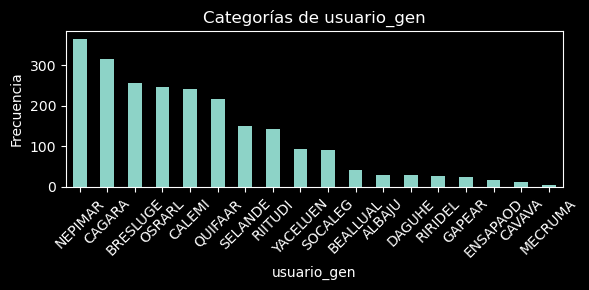

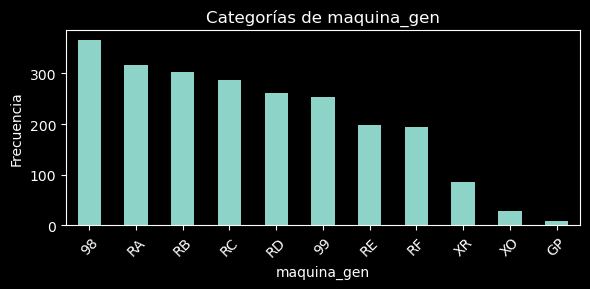

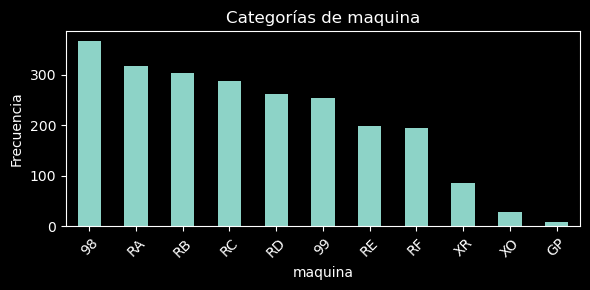

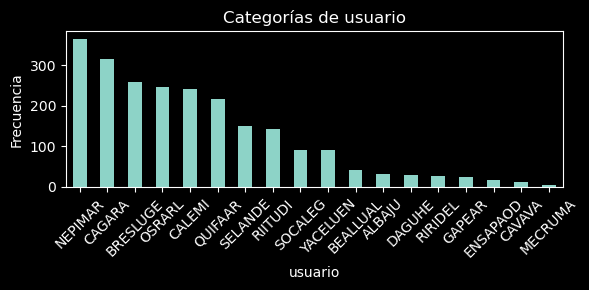

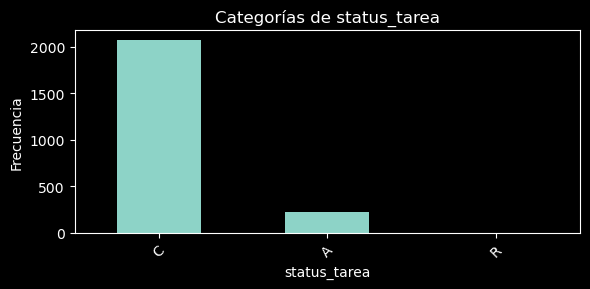

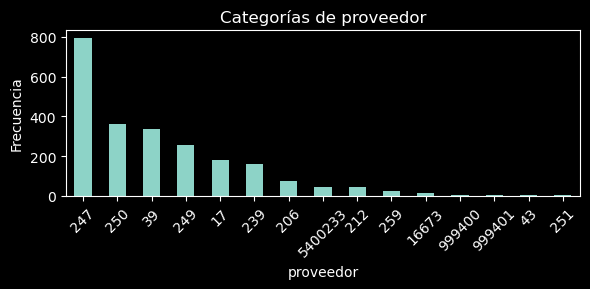

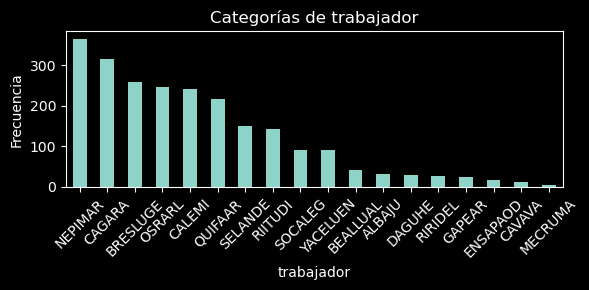

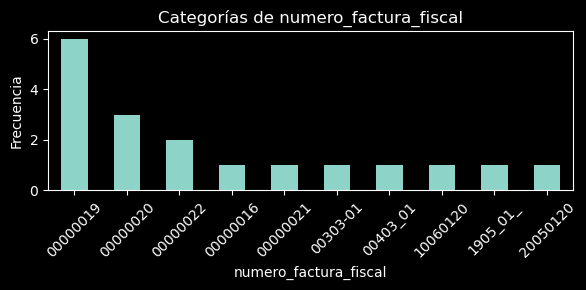

In [45]:
# Frecuencias de las categóricas de baja cardinalidad (estilo recibo.ipynb).
cat_cols = [
    c for c in df_limpio.select_dtypes(include="category").columns
    if 1 < df_limpio[c].nunique() <= 25 and c != "numero_pedido"
]

for col in cat_cols:
    counts = df_limpio[col].value_counts()
    fig, ax = plt.subplots(figsize=(6, 3))
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Categorías de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

## 6. Dashboard de carga de trabajo por hora (handhelds)

**Objetivo de negocio:** conocer la *carga de trabajo por hora* de los empleados que
registran movimientos de almacén con handhelds, y saber **qué usuarios están activos en
cada hora del día**.

**Fuente de datos:** el endpoint SGA `sga_entradas` ya devuelve las fechas **con hora**
(`fecha_gen` / `fecha_inicio` / `fecha_fin` traen `HH:MM:SS` reales), así que esta sección
**reutiliza el `df_limpio` del API** de las secciones 1–5 — la misma y única fuente de la
verdad. (Hasta hace poco el API truncaba la hora y este dashboard leía la BD Zeus
`ds_entradas`; esa excepción quedó **resuelta** cuando el API empezó a enviar la hora.)

Usamos **`fecha_inicio`** como el instante en que el empleado arrancó la tarea en la
handheld (mejor proxy de "trabajo ocurrido a esta hora"). La ventana del dashboard sigue al
parámetro **`FECHA_GEN`** (que actúa como cota inferior): para una vista de varios meses,
pon `FECHA_GEN` más temprano (p. ej. `"01/01/2026"`).

In [46]:
# --- Fuente CON hora: el API SGA ya entrega fecha_inicio/fecha_fin con HH:MM:SS reales ---
# Reutilizamos el df_limpio de las secciones 1–3 (misma fuente única); ya no se lee la BD Zeus.
ent = df_limpio[df_limpio["fecha_inicio"].notna()].copy()

# Usuarios de negocio: excluimos cuentas de sistema y nulos (configurable).
SYS_USERS = {"ADMIN", "", None}
ent = ent[ent["usuario"].notna() & ~ent["usuario"].isin(SYS_USERS)].copy()

ent["hora"] = ent["fecha_inicio"].dt.hour
ent["fecha"] = ent["fecha_inicio"].dt.normalize()  # día (sin hora)
DOW_ES = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ent["dia_sem"] = pd.Categorical(
    ent["fecha_inicio"].dt.dayofweek.map(dict(enumerate(DOW_ES))),
    categories=DOW_ES, ordered=True,
)

# Duración de la tarea (min). Hay tareas abandonadas que cruzan días; las acotamos para que
# la métrica de "minutos ocupados" no se contamine (cap 30 min; el p95 real ≈ 5 min).
DUR_CAP_MIN = 30
ent["dur_min"] = (ent["fecha_fin"] - ent["fecha_inicio"]).dt.total_seconds() / 60.0
ent.loc[(ent["dur_min"] < 0) | (ent["dur_min"] > DUR_CAP_MIN), "dur_min"] = np.nan

print(f"Para el dashboard: {len(ent):,} tareas | {ent['usuario'].nunique()} usuarios | "
      f"{ent['maquina'].nunique()} handhelds | {ent['fecha'].nunique()} días "
      f"({ent['fecha'].min():%d-%b} a {ent['fecha'].max():%d-%b-%Y})")

Para el dashboard: 2,306 tareas | 18 usuarios | 11 handhelds | 67 días (03-Mar a 22-Jun-2026)


### 6.1 Rejilla de análisis (2 columnas × 4 filas)

| # | Panel | Pregunta que responde |
|---|---|---|
| 1 | Tareas por hora del día | ¿A qué horas se concentra la carga de trabajo? |
| 2 | Usuarios activos por hora | ¿Cuántos empleados trabajan en cada hora? |
| 3 | Heatmap **usuario × hora** | ¿Qué usuario está activo y a qué hora? *(centro del análisis)* |
| 4 | Heatmap día de semana × hora | ¿Cómo cambia el patrón horario según el día? |
| 5 | Carga total por usuario | ¿Quién soporta más carga? (ranking) |
| 6 | Minutos ocupados por hora | Intensidad en tiempo, no solo número de tareas |
| 7 | Heatmap handheld × hora | ¿Qué dispositivos se usan y cuándo? |
| 8 | Serie de tiempo (tareas/día) | Evolución y estacionalidad semanal |

`TOP_N` acota los paneles por entidad (usuario/handheld) para que sean legibles; ajústalo
según lo que quieras ver.

10:01:12 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
10:01:12 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
10:01:12 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
10:01:12 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
C:\Users\ObedGarcíaOjeda\AppData\Local\Temp\ipykernel_5600\1057360945.py:31: FutureWarning: The default value of observed=False is deprecated and will change to observed=True i

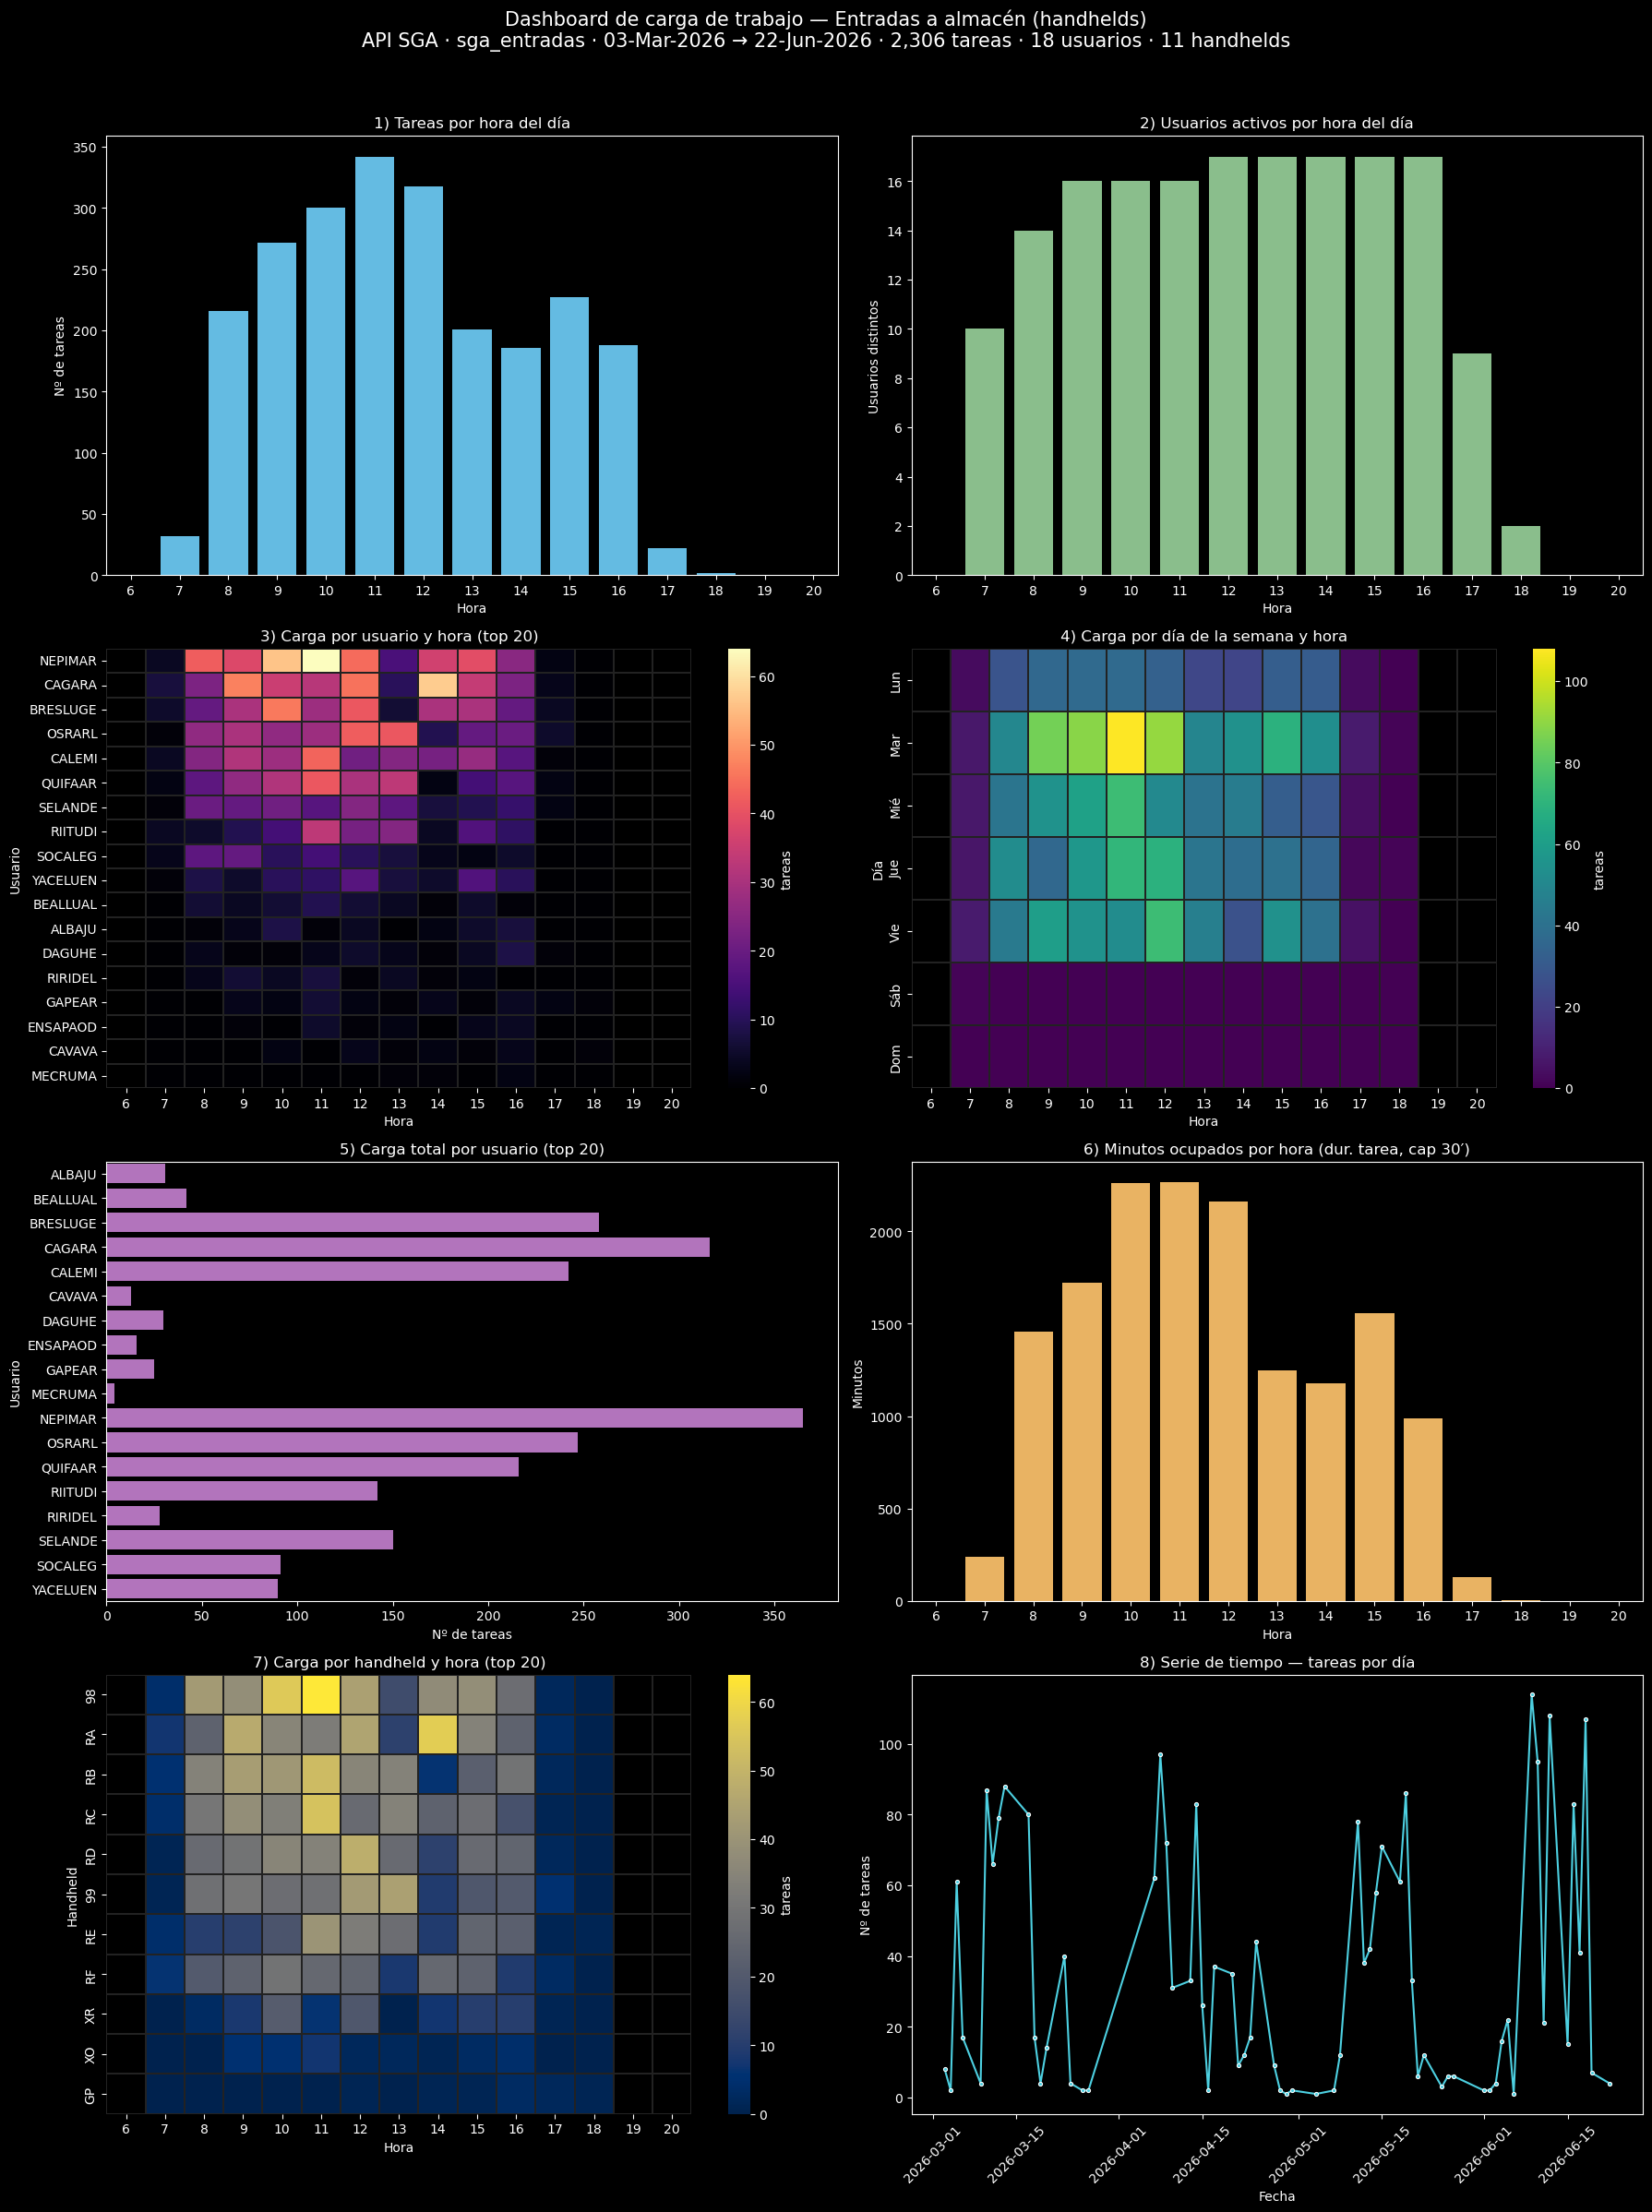

In [47]:
# Rejilla 2 columnas × 4 filas (seaborn). Heatmaps/ranking acotados a TOP_N por legibilidad.
TOP_N = 20
HORAS = list(range(6, 21))  # ventana laboral observada (06h–20h)

top_users = ent["usuario"].value_counts().head(TOP_N).index.tolist()
top_maqs = ent["maquina"].value_counts().head(TOP_N).index.tolist()

fig, axes = plt.subplots(4, 2, figsize=(18, 24))
fig.suptitle(
    "Dashboard de carga de trabajo — Entradas a almacén (handhelds)\n"
    f"API SGA · sga_entradas · {ent['fecha'].min():%d-%b-%Y} → {ent['fecha'].max():%d-%b-%Y} · "
    f"{len(ent):,} tareas · {ent['usuario'].nunique()} usuarios · {ent['maquina'].nunique()} handhelds",
    fontsize=15, y=0.997,
)

# (1) Tareas por hora del día — curva global de carga.
ax = axes[0, 0]
s = ent.groupby("hora").size().reindex(HORAS, fill_value=0)
sns.barplot(x=s.index, y=s.values, ax=ax, color="#4FC3F7")
ax.set(title="1) Tareas por hora del día", xlabel="Hora", ylabel="Nº de tareas")

# (2) Usuarios activos por hora del día — cuántos empleados trabajan en cada hora.
ax = axes[0, 1]
s = ent.groupby("hora")["usuario"].nunique().reindex(HORAS, fill_value=0)
sns.barplot(x=s.index, y=s.values, ax=ax, color="#81C784")
ax.set(title="2) Usuarios activos por hora del día", xlabel="Hora", ylabel="Usuarios distintos")

# (3) Heatmap usuario × hora — centro del análisis: ¿quién está activo y a qué hora?
ax = axes[1, 0]
piv = (ent[ent["usuario"].isin(top_users)]
       .pivot_table(index="usuario", columns="hora", values="fecha_inicio", aggfunc="count")
       .reindex(index=top_users, columns=HORAS))
sns.heatmap(piv, ax=ax, cmap="magma", cbar_kws={"label": "tareas"}, linewidths=.3, linecolor="#222")
ax.set(title=f"3) Carga por usuario y hora (top {TOP_N})", xlabel="Hora", ylabel="Usuario")

# (4) Heatmap día de la semana × hora — cómo cambia el patrón horario por día.
ax = axes[1, 1]
piv = (ent.pivot_table(index="dia_sem", columns="hora", values="fecha_inicio",
                       aggfunc="count", observed=False).reindex(columns=HORAS))
sns.heatmap(piv, ax=ax, cmap="viridis", cbar_kws={"label": "tareas"}, linewidths=.3, linecolor="#222")
ax.set(title="4) Carga por día de la semana y hora", xlabel="Hora", ylabel="Día")

# (5) Ranking de carga por usuario.
ax = axes[2, 0]
s = ent["usuario"].value_counts().head(TOP_N)
sns.barplot(x=s.values, y=s.index, ax=ax, color="#BA68C8")
ax.set(title=f"5) Carga total por usuario (top {TOP_N})", xlabel="Nº de tareas", ylabel="Usuario")

# (6) Minutos ocupados por hora — intensidad en tiempo, no solo conteo.
ax = axes[2, 1]
s = ent.groupby("hora")["dur_min"].sum().reindex(HORAS, fill_value=0)
sns.barplot(x=s.index, y=s.values, ax=ax, color="#FFB74D")
ax.set(title=f"6) Minutos ocupados por hora (dur. tarea, cap {DUR_CAP_MIN}′)", xlabel="Hora", ylabel="Minutos")

# (7) Heatmap handheld (maquina) × hora — qué dispositivos se usan y cuándo.
ax = axes[3, 0]
piv = (ent[ent["maquina"].isin(top_maqs)]
       .pivot_table(index="maquina", columns="hora", values="fecha_inicio", aggfunc="count")
       .reindex(index=top_maqs, columns=HORAS))
sns.heatmap(piv, ax=ax, cmap="cividis", cbar_kws={"label": "tareas"}, linewidths=.3, linecolor="#222")
ax.set(title=f"7) Carga por handheld y hora (top {TOP_N})", xlabel="Hora", ylabel="Handheld")

# (8) Serie de tiempo — tareas por día (estacionalidad semanal).
ax = axes[3, 1]
s = ent.groupby("fecha").size()
sns.lineplot(x=s.index, y=s.values, ax=ax, color="#4DD0E1", marker="o", markersize=3)
ax.set(title="8) Serie de tiempo — tareas por día", xlabel="Fecha", ylabel="Nº de tareas")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

### 6.2 Lectura de negocio (prototipo)

Sobre el rango cargado (definido por `FECHA_GEN`, fuente API SGA):

- **Doble pico de carga**: por la mañana (≈07–09h) y un pico fuerte por la tarde
  (≈16–18h, máximo alrededor de las 17h). Las horas valle (≈10–14h) son candidatas para
  reasignar personal o adelantar/atrasar tareas.
- **Concentración semanal**: la actividad es de lunes a viernes; el sábado es marginal y
  el domingo prácticamente nulo (ver panel 4).
- **Carga desigual entre usuarios**: unos pocos usuarios concentran la mayor parte de las
  tareas (cola larga en el panel 5) — insumo directo para balancear turnos.
- **Duración por tarea baja** (mediana < 1 min, p95 ≈ 5 min): la carga se explica sobre
  todo por **volumen de tareas por hora**, más que por tareas largas.

**Caveats del prototipo:**

- El instante usado es `fecha_inicio` (arranque de la tarea en la handheld); podría
  afinarse cruzando con `fecha_fin` para medir solapamiento/ocupación real por hora.
- Se excluyen cuentas de sistema (`ADMIN`) y nulos vía `SYS_USERS` (configurable).
- Las tareas abandonadas que cruzan días se acotan a `DUR_CAP_MIN` solo para la métrica de
  minutos ocupados (panel 6).
- El dashboard sigue al rango de `FECHA_GEN` (cota inferior); para más historia, baja
  `FECHA_GEN`. El API ya entrega la hora real, así que es la **fuente única** — ya no se
  complementa con la BD Zeus `ds_entradas`.